In [5]:
import numpy as np
import pandas as pd
import time

In [6]:
df = pd.read_csv("/home/ipartzix/ML-Dataset/Social_Network_Ads.csv")

In [7]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [8]:
df = df[['Age','EstimatedSalary','Purchased']]

In [9]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [10]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [11]:
X

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [13]:
X_scaled.shape

(400, 2)

In [14]:
#from sklearn.model_selection import train_test_split
#X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [15]:
#X_train.shape

In [16]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [17]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

/home/ipartzix/miniconda3/envs/MLE/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

### batch_size = 1 it mean stocastic GD

In [19]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
#start = time.time()
history = model.fit(X_scaled,y,epochs=500,batch_size=1,validation_split=0.2)
#print(time.time() - start)

Epoch 1/500
320/320 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7656 - loss: 0.5352 - val_accuracy: 0.7250 - val_loss: 0.6080
Epoch 2/500
320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8438 - loss: 0.3743 - val_accuracy: 0.8250 - val_loss: 0.5160
Epoch 3/500
320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8687 - loss: 0.3186 - val_accuracy: 0.8750 - val_loss: 0.4102
Epoch 4/500
320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8687 - loss: 0.2909 - val_accuracy: 0.8875 - val_loss: 0.3488
Epoch 5/500
320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8594 - loss: 0.2823 - val_accuracy: 0.9125 - val_loss: 0.3040
Epoch 6/500
320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8656 - loss: 0.2780 - val_accuracy: 0.9125 - val_loss: 0.2723
Epoch 7/500
320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8719 - loss: 0.2758 - val_accuracy: 0.9125 - val_loss: 0.2618
Epoch 8/500
320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8687 - loss: 0.2752 - val_accu

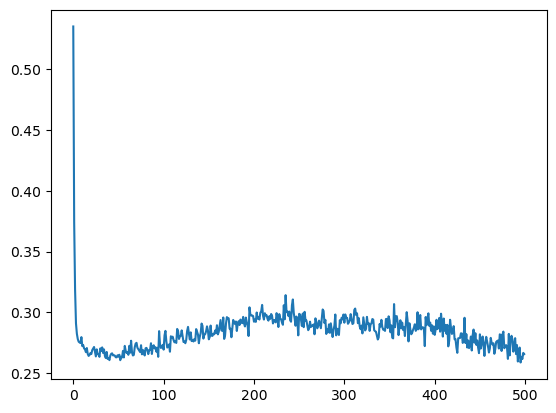

In [20]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])

In [21]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

### batch_size = n (n= any number of batch) it mean batch GD

In [22]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
#start = time.time()
history = model.fit(X_scaled,y,epochs=10,batch_size=250,validation_split=0.2)
#print(time.time() - start)

Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 311ms/step - accuracy: 0.3344 - loss: 0.6832 - val_accuracy: 0.7750 - val_loss: 0.5610
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.5719 - loss: 0.6642 - val_accuracy: 0.7750 - val_loss: 0.5589
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.7094 - loss: 0.6517 - val_accuracy: 0.8000 - val_loss: 0.5589
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.8094 - loss: 0.6412 - val_accuracy: 0.8000 - val_loss: 0.5598
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.8313 - loss: 0.6325 - val_accuracy: 0.8000 - val_loss: 0.5592
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.8375 - loss: 0.6245 - val_accuracy: 0.8125 - val_loss: 0.5597
Epoch 7/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.8438 - loss: 0.6170 - val_accuracy: 0.8250 - val_loss: 0.5574
Epoch 8/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.8438 - loss: 0.6101 - val_accuracy: 0.8625 - val_loss: 

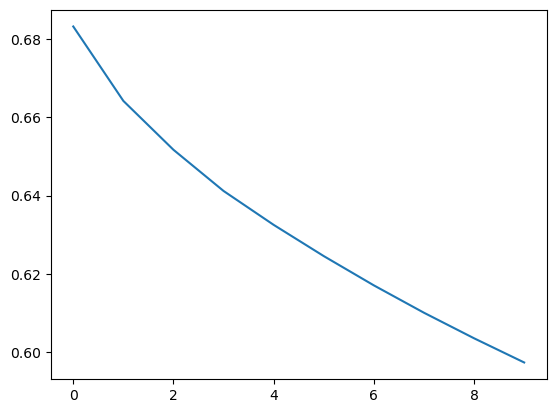

In [23]:
plt.plot(history.history['loss'])